# Unit00_Local_Environment_Setup | Windows 本地環境設定與實作演練

本 Notebook 提供 Windows 本地開發環境（Miniconda + `PY310` 虛擬環境 + Jupyter Notebook/Lab）的完整實作演練，並內建跨平台相容設計（可同時於 **Windows 本地端 `PY310` 環境**與 **Google Colab 雲端環境**中無縫執行）。

## 目標
- 掌握本課程標準的跨環境路徑設定（本地端工作目錄 vs Colab 自動掛載與 Symlink 架構）
- 驗證 Python 3.10 執行環境、Conda 虛擬環境狀態與系統硬體資源（CPU、RAM、磁碟空間）
- 檢查核心科學計算套件、進階梯度提升樹套件與 TensorFlow 深度學習環境版本
- 驗證本地端 NVIDIA GPU（CUDA 11.2 / cuDNN 8.1）硬體加速狀態與矩陣運算效能
- 實作 NumPy 數值與線性代數運算、Pandas 化工製程數據處理與本地 CSV 檔案讀寫
- 實作 Matplotlib 多子圖科學視覺化與 Scikit-learn 線性回歸建模及殘差診斷流程

**注意事項：**
- 請確認已依照教學講義 [Unit00_Local_Environment_Setup.md](Unit00_Local_Environment_Setup.md) 完成 Miniconda 安裝
- 請確認已透過 [PY310_environment.yml](PY310_environment.yml) 建立並啟動 `PY310` 虛擬環境
- 在 Anaconda Prompt 中執行：`conda activate PY310` 然後輸入 `jupyter notebook` 或 `jupyter lab`

---
### 0. 環境設定

In [1]:
from pathlib import Path
import os

# ========================================
# 路徑設定 (兼容 Colab 與 Local)
# ========================================
UNIT_OUTPUT_DIR = 'P0_Unit00_Local_Environment_Setup'

try:
    from google.colab import drive
    IN_COLAB = True
    print("✓ 偵測到 Colab 環境，準備掛載 Google Drive...")
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    IN_COLAB = False
    print("✓ 偵測到 Local 環境")

try:
    shortcut_path = '/content/ChemE-3590'
    os.remove(shortcut_path)
except (FileNotFoundError, OSError):
    pass

if IN_COLAB:
    source_path = Path('/content/drive/My Drive/Colab Notebooks/ChemE-3590')
    os.symlink(source_path, shortcut_path)
    shortcut_path = Path(shortcut_path)
    if source_path.exists():
        NOTEBOOK_DIR = shortcut_path / 'Part_0'
        OUTPUT_DIR   = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
        FIG_DIR      = OUTPUT_DIR / 'figs'
    else:
        print("⚠️ 找不到雲端 ChemE-3590 路徑，將使用當前目錄作為工作目錄")
        NOTEBOOK_DIR = Path.cwd()
        OUTPUT_DIR   = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
        FIG_DIR      = OUTPUT_DIR / 'figs'
else:
    NOTEBOOK_DIR = Path.cwd()
    OUTPUT_DIR   = NOTEBOOK_DIR / 'outputs' / UNIT_OUTPUT_DIR
    FIG_DIR      = OUTPUT_DIR / 'figs'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"\n✓ Notebook工作目錄: {NOTEBOOK_DIR}")
print(f"✓ 結果輸出目錄: {OUTPUT_DIR}")
print(f"✓ 圖檔輸出目錄: {FIG_DIR}")

✓ 偵測到 Local 環境

✓ Notebook工作目錄: D:\MyGit\ChemE-3590\Part_0
✓ 結果輸出目錄: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Local_Environment_Setup
✓ 圖檔輸出目錄: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Local_Environment_Setup\figs


---
### 1. 載入套件

In [2]:
import sys
import platform
import shutil
import subprocess
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import tensorflow as tf

# 設定隨機種子以確保結果可重現
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# 繪圖樣式設定
plt.rcParams.update({
    'figure.dpi': 100,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'lines.linewidth': 2,
    'axes.unicode_minus': False,
})

print("✓ 套件載入完成")
print(f"  Python       版本: {sys.version.split()[0]}")
print(f"  numpy        版本: {np.__version__}")
print(f"  scipy        版本: {scipy.__version__}")
print(f"  pandas       版本: {pd.__version__}")
print(f"  matplotlib   版本: {matplotlib.__version__}")
print(f"  seaborn      版本: {sns.__version__}")
print(f"  scikit-learn 版本: {sklearn.__version__}")
print(f"  tensorflow   版本: {tf.__version__}")

✓ 套件載入完成
  Python       版本: 3.10.19
  numpy        版本: 1.26.4
  scipy        版本: 1.15.2
  pandas       版本: 2.3.3
  matplotlib   版本: 3.10.8
  seaborn      版本: 0.13.2
  scikit-learn 版本: 1.7.2
  tensorflow   版本: 2.10.1


---
### 2. 環境驗證與硬體資源檢查

#### 2.1 檢查 Python 執行環境、Conda 虛擬環境與系統硬體資訊

在本地端開發時，最重要的第一步是確認目前的 Jupyter Kernel 確實運行於我們建立的 `PY310` 虛擬環境中（可透過 `sys.executable` 路徑與 `CONDA_DEFAULT_ENV` 環境變數雙重驗證），並檢視電腦的 CPU、實體記憶體（RAM）與硬碟可用空間。

In [3]:
conda_env = os.environ.get('CONDA_DEFAULT_ENV', Path(sys.prefix).name)

print("=" * 68)
print("Python Environment & System Hardware Information")
print("=" * 68)
print(f"Python Version    : {sys.version}")
print(f"Python Executable : {sys.executable}")
print(f"Active Conda Env  : {conda_env}")
print(f"Operating System  : {platform.platform()}")
print(f"Architecture      : {platform.architecture()[0]} ({platform.machine()})")
print(f"Processor         : {platform.processor()}")

# 檢查系統記憶體 (RAM) 與磁碟空間 (兼容 Windows 與 Linux/Colab)
if platform.system() == 'Windows':
    import ctypes
    class MEMORYSTATUSEX(ctypes.Structure):
        _fields_ = [
            ("dwLength", ctypes.c_ulong),
            ("dwMemoryLoad", ctypes.c_ulong),
            ("ullTotalPhys", ctypes.c_ulonglong),
            ("ullAvailPhys", ctypes.c_ulonglong),
            ("ullTotalPageFile", ctypes.c_ulonglong),
            ("ullAvailPageFile", ctypes.c_ulonglong),
            ("ullTotalVirtual", ctypes.c_ulonglong),
            ("ullAvailVirtual", ctypes.c_ulonglong),
            ("sullAvailExtendedVirtual", ctypes.c_ulonglong),
        ]
    stat = MEMORYSTATUSEX(dwLength=ctypes.sizeof(MEMORYSTATUSEX))
    ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(stat))
    print(f"System RAM        : Total {stat.ullTotalPhys / (1024**3):.2f} GB | Available {stat.ullAvailPhys / (1024**3):.2f} GB")
elif Path('/proc/meminfo').exists():
    with open('/proc/meminfo') as f:
        for line in f:
            if 'MemTotal' in line:
                mem_kb = int(line.split()[1])
                print(f"System RAM        : Total {mem_kb / (1024**2):.2f} GB")
                break

total_disk, used_disk, free_disk = shutil.disk_usage(NOTEBOOK_DIR)
print(f"Disk Space        : Total {total_disk / (1024**3):.1f} GB | Used {used_disk / (1024**3):.1f} GB | Free {free_disk / (1024**3):.1f} GB")

yml_path = NOTEBOOK_DIR / 'PY310_environment.yml'
print(f"Env YAML File     : {yml_path.name} (Exists: {yml_path.exists()})")
print("=" * 68)

Python Environment & System Hardware Information
Python Version    : 3.10.19 | packaged by conda-forge | (main, Oct 22 2025, 22:23:22) [MSC v.1944 64 bit (AMD64)]
Python Executable : C:\Users\Yao-ChenChuang\miniconda3\envs\PY310\python.exe
Active Conda Env  : PY310
Operating System  : Windows-10-10.0.26200-SP0
Architecture      : 64bit (AMD64)
Processor         : Intel64 Family 6 Model 85 Stepping 7, GenuineIntel
System RAM        : Total 127.69 GB | Available 66.62 GB
Disk Space        : Total 465.8 GB | Used 214.8 GB | Free 251.0 GB
Env YAML File     : PY310_environment.yml (Exists: True)


#### 2.2 檢查進階機器學習與深度學習生態系套件

本課程提供的 `PY310_environment.yml` 除預裝基礎科學計算套件外，亦完整涵蓋非監督式降維（`umap-learn`）、關聯規則（`mlxtend`）、網路拓樸分析（`networkx`）、梯度提升樹家族（`xgboost`、`lightgbm`、`catboost`）、互動式控制項（`ipywidgets`）與深度學習框架（`tensorflow`、`tensorboard`）。以下逐一驗證其安裝狀態與版本。

In [4]:
import importlib

packages_to_check = [
    ('TensorFlow',       'tensorflow',  'Part 4: DNN / CNN / RNN 深度學習框架'),
    ('TensorBoard',      'tensorboard', 'Part 4: 深度學習訓練歷程視覺化'),
    ('XGBoost',          'xgboost',     'Part 3: 梯度提升決策樹 (支援 GPU 加速)'),
    ('LightGBM',         'lightgbm',    'Part 3: 高效直方圖梯度提升樹'),
    ('CatBoost',         'catboost',    'Part 3: 對稱樹梯度提升演算法'),
    ('UMAP-learn',       'umap',        'Part 2: 流形學習非線性降維 (Unit06)'),
    ('ipywidgets',       'ipywidgets',  'Part 0: Jupyter 互動式介面控制項'),
    ('mlxtend',          'mlxtend',     'Part 2: Apriori / FP-Growth 關聯規則 (Unit08)'),
    ('NetworkX',         'networkx',    'Part 2: 網路拓樸與關聯圖分析'),
    ('OpenPyXL',         'openpyxl',    'Part 1: Excel (.xlsx) 試算表讀寫支援'),
]

print("=" * 82)
print(f"{'Package Name':18s} | {'Version':12s} | {'Course Application'}")
print("-" * 82)
for display_name, mod_name, desc in packages_to_check:
    try:
        mod = importlib.import_module(mod_name)
        ver = getattr(mod, '__version__', 'Installed')
        print(f"✓ {display_name:16s} | {ver:12s} | {desc}")
    except ImportError:
        print(f"✗ {display_name:16s} | {'Missing':12s} | {desc}")
print("=" * 82)

Package Name       | Version      | Course Application
----------------------------------------------------------------------------------
✓ TensorFlow       | 2.10.1       | Part 4: DNN / CNN / RNN 深度學習框架
✓ TensorBoard      | 2.10.1       | Part 4: 深度學習訓練歷程視覺化
✓ XGBoost          | 1.7.6        | Part 3: 梯度提升決策樹 (支援 GPU 加速)
✓ LightGBM         | 4.6.0        | Part 3: 高效直方圖梯度提升樹
✓ CatBoost         | 1.2.7        | Part 3: 對稱樹梯度提升演算法


✓ UMAP-learn       | 0.5.11       | Part 2: 流形學習非線性降維 (Unit06)
✓ ipywidgets       | 8.1.8        | Part 0: Jupyter 互動式介面控制項
✓ mlxtend          | 0.24.0       | Part 2: Apriori / FP-Growth 關聯規則 (Unit08)


✓ NetworkX         | 3.4          | Part 2: 網路拓樸與關聯圖分析


✓ OpenPyXL         | 3.1.5        | Part 1: Excel (.xlsx) 試算表讀寫支援


#### 2.3 檢查本地 NVIDIA GPU 與 CUDA / cuDNN 加速狀態

**技術重點說明**：在 Windows 原生環境（Native Windows）中，**TensorFlow 2.10.1 是最後一個直接支援本地 NVIDIA GPU 加速的官方版本**（自 TensorFlow 2.11 起在 Windows 下若不使用 WSL2 則僅支援 CPU）。本課程的 `PY310_environment.yml` 已在 Conda 環境內直接整合 `cudatoolkit=11.2` 與 `cudnn=8.1`，無須在 Windows 系統層級手動安裝 CUDA Toolkit 即可直接啟用 GPU 加速。

以下檢查 TensorFlow 是否偵測到本地 GPU、設定動態記憶體成長（Memory Growth），並進行 $2000 \times 2000$ 矩陣乘法運算測試。

In [5]:
print("=" * 68)
print("TensorFlow GPU & CUDA Acceleration Check")
print("=" * 68)
print(f"TensorFlow Version      : {tf.__version__}")
print(f"Built with CUDA Support : {tf.test.is_built_with_cuda()}")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU Devices Detected    : {len(gpus)} device(s)")
    for idx, gpu in enumerate(gpus):
        details = tf.config.experimental.get_device_details(gpu)
        dev_name = details.get('device_name', 'NVIDIA GPU')
        cc = details.get('compute_capability', 'N/A')
        print(f"  -> GPU {idx}: {gpu.name} | {dev_name} (Compute Capability: {cc})")
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("Memory Growth Policy    : Enabled (Dynamic VRAM allocation)")
    except RuntimeError as e:
        print(f"Memory Growth Note      : {e}")
else:
    print("GPU Devices Detected    : 0 (Running on CPU mode)")

# 測試 TensorFlow 張量矩陣乘法運算
tf.random.set_seed(SEED)
mat_size = 2000
a_tensor = tf.random.normal([mat_size, mat_size])
b_tensor = tf.random.normal([mat_size, mat_size])

# 預熱與計時
_ = tf.matmul(a_tensor, b_tensor)
t0 = time.perf_counter()
c_tensor = tf.matmul(a_tensor, b_tensor)
elapsed_ms = (time.perf_counter() - t0) * 1000
print(f"Tensor MatMul ({mat_size}x{mat_size}) : Completed on {c_tensor.device} in {elapsed_ms:.2f} ms")
print("=" * 68)

TensorFlow GPU & CUDA Acceleration Check
TensorFlow Version      : 2.10.1
Built with CUDA Support : True
GPU Devices Detected    : 1 device(s)
  -> GPU 0: /physical_device:GPU:0 | NVIDIA GeForce RTX 4090 (Compute Capability: (8, 9))
Memory Growth Policy    : Enabled (Dynamic VRAM allocation)


Tensor MatMul (2000x2000) : Completed on /job:localhost/replica:0/task:0/device:GPU:0 in 0.55 ms


**環境與硬體檢核分析**：
- **虛擬環境隔離驗證**：`Python Executable` 明確指向 `...\miniconda3\envs\PY310\python.exe`，且 `Active Conda Env` 為 `PY310`，證實目前 Jupyter Kernel 已正確綁定至本課程獨立虛擬環境，而非系統預設的 `base` 環境。
- **原生 Windows GPU 硬體加速**：TensorFlow 2.10.1 成功載入 `PY310\Library\bin` 目錄下的 CUDA 11.2 / cuDNN 8.1 動態連結庫，正確識別出本地端顯示卡（`NVIDIA GeForce RTX 4090`，Compute Capability `8.9`），並啟用動態顯存分配（Memory Growth）。在 $2000 \times 2000$ 浮點數張量矩陣乘法測試中，於 `/device:GPU:0` 上僅耗時 $0.55$ ms 即完成運算。

---
### 3. 基本功能測試

#### 3.1 NumPy 數值運算與線性代數測試

NumPy 是 Python 科學計算的核心基石。在化學工程中，無論是實驗數據的統計分析（計算樣本平均數 $\mu$ 與標準差 $\sigma$ ）、多組分質量平衡聯立方程組 $A \mathbf{x} = \mathbf{b}$ 求解，或是矩陣乘法運算，皆仰賴 NumPy 的高效率向量化陣列操作：

$$
A = \begin{bmatrix} 1 & 2 \\ 3 & 4 \end{bmatrix}, \quad B = \begin{bmatrix} 5 & 6 \\ 7 & 8 \end{bmatrix}, \quad C = A B = \begin{bmatrix} 19 & 22 \\ 43 & 50 \end{bmatrix}, \quad A \mathbf{x} = \begin{bmatrix} 5 \\ 11 \end{bmatrix} \implies \mathbf{x} = \begin{bmatrix} 1 \\ 2 \end{bmatrix}
$$

In [6]:
print("=" * 68)
print("NumPy Array & Linear Algebra Operations Test")
print("=" * 68)

# 1. 一維陣列與基本統計運算
arr = np.array([1, 2, 3, 4, 5])
print(f"1D Array       : {arr} (dtype: {arr.dtype}, shape: {arr.shape})")
print(f"  Mean         : {arr.mean():.2f}")
print(f"  Std Dev      : {arr.std():.4f}")
print(f"  Sum          : {arr.sum()}")
print(f"  Min / Max    : {arr.min()} / {arr.max()}")

# 2. 二維矩陣乘法與行列式計算
matrix_a = np.array([[1, 2], [3, 4]])
matrix_b = np.array([[5, 6], [7, 8]])
matrix_c = matrix_a @ matrix_b
det_a = np.linalg.det(matrix_a)

print(f"\nMatrix A:\n{matrix_a}")
print(f"Matrix B:\n{matrix_b}")
print(f"Matrix Multiplication (C = A @ B):\n{matrix_c}")
print(f"Determinant of A : {det_a:.2f}")

# 3. 求解線性聯立方程組 A * x = b (例如雙組分質量平衡)
rhs_b = np.array([5.0, 11.0])
sol_x = np.linalg.solve(matrix_a, rhs_b)
print(f"Linear System Solution (A * x = {rhs_b}) -> x = {sol_x}")

# 4. 固定隨機種子之標準常態分布抽樣
np.random.seed(SEED)
random_data = np.random.randn(5)
print(f"\nRandom Standard Normal Sample (seed={SEED}):")
print(f"  {np.round(random_data, 4)}")

print("\n✓ NumPy numerical and linear algebra operations working correctly!")
print("=" * 68)

NumPy Array & Linear Algebra Operations Test
1D Array       : [1 2 3 4 5] (dtype: int32, shape: (5,))
  Mean         : 3.00
  Std Dev      : 1.4142
  Sum          : 15
  Min / Max    : 1 / 5

Matrix A:
[[1 2]
 [3 4]]
Matrix B:
[[5 6]
 [7 8]]
Matrix Multiplication (C = A @ B):
[[19 22]
 [43 50]]
Determinant of A : -2.00
Linear System Solution (A * x = [ 5. 11.]) -> x = [1. 2.]

Random Standard Normal Sample (seed=42):
  [ 0.4967 -0.1383  0.6477  1.523  -0.2342]

✓ NumPy numerical and linear algebra operations working correctly!


**結果驗證說明**：
- **向量化統計計算**：一維陣列 `[1, 2, 3, 4, 5]` 的平均值 $\mu = 3.00$ ，母體標準差 $\sigma = \sqrt{\frac{1}{5}\sum_{i=1}^5 (x_i - 3)^2} = \sqrt{2} \approx 1.4142$ ，計算結果完全精確。
- **線性代數與聯立方程組求解**：係數矩陣 $A$ 的行列式 $\det(A) = 1 \times 4 - 2 \times 3 = -2.00 \neq 0$ （非奇異可逆矩陣），透過 `np.linalg.solve(A, b)` 解得雙組分質量平衡聯立方程組 $A \mathbf{x} = [5.0, 11.0]^T$ 之唯一解 $\mathbf{x} = [1.0, 2.0]^T$ ，驗證了底層 BLAS / LAPACK 線性代數加速函式庫運作正常。

#### 3.2 Pandas 化工製程資料處理與本地檔案讀寫測試

以下模擬一座**間歇式反應器（Batch Reactor）**共 $N = 12$ 個批次的操作紀錄，包含四個欄位：
- `Batch_ID`：批次編號（`B001` 至 `B012`）
- `Temperature_C`：反應溫度 $T \in [60, 80]$ °C
- `Pressure_bar`：反應壓力 $P \in [1.0, 2.0]$ bar
- `Reaction_Time_hr`：反應時間 $t \in [2.0, 4.0]$ hr
- `Yield_percent`：批次產率 $Y$ （%），受溫度、壓力與反應時間正向影響並含微小量測雜訊：

$$
Y = 25.0 + 0.65 \, T + 5.0 \, P + 2.5 \, t + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1.0^2)
$$

我們使用 Pandas 進行統計摘要、高產率批次篩選（ $Y > 85\%$ ）、計算皮爾森相關係數矩陣（Pearson Correlation Matrix），並將表格輸出為 CSV 檔案至本地 `OUTPUT_DIR` 目錄驗證檔案讀寫功能。

In [7]:
print("=" * 68)
print("Pandas DataFrame Operations & File I/O Test")
print("=" * 68)

# 建立具物理關聯性的模擬間歇式反應器數據
np.random.seed(SEED)
n_batches = 12
temp_c = np.random.uniform(60.0, 80.0, n_batches)
press_bar = np.random.uniform(1.0, 2.0, n_batches)
time_hr = np.random.uniform(2.0, 4.0, n_batches)
noise = np.random.normal(0.0, 1.0, n_batches)

yield_pct = np.clip(25.0 + 0.65 * temp_c + 5.0 * press_bar + 2.5 * time_hr + noise, 0.0, 100.0)

df = pd.DataFrame({
    'Batch_ID': [f'B{i:03d}' for i in range(1, n_batches + 1)],
    'Temperature_C': temp_c,
    'Pressure_bar': press_bar,
    'Reaction_Time_hr': time_hr,
    'Yield_percent': yield_pct
})

print("1. Batch Reactor Process Data (12 Batches):")
print(df.round(2).to_string(index=False))

print("\n" + "-" * 68)
print("2. Descriptive Statistical Summary:")
print(df.describe().round(2).to_string())

# 篩選高產率批次 (Yield > 85%)
high_yield_df = df[df['Yield_percent'] > 85.0].sort_values(by='Yield_percent', ascending=False)
print("\n" + "-" * 68)
print(f"3. High Yield Batches (Yield > 85%, Count = {len(high_yield_df)}):")
print(high_yield_df.round(2).to_string(index=False))

# 計算相關係數矩陣
num_cols = ['Temperature_C', 'Pressure_bar', 'Reaction_Time_hr', 'Yield_percent']
corr_matrix = df[num_cols].corr()
print("\n" + "-" * 68)
print("4. Pearson Correlation Matrix:")
print(corr_matrix.round(3).to_string())

# 測試本地端 CSV 檔案儲存與讀取
csv_path = OUTPUT_DIR / 'batch_reactor_data.csv'
df.to_csv(csv_path, index=False, encoding='utf-8-sig')
df_reloaded = pd.read_csv(csv_path)
print("\n" + "-" * 68)
print(f"5. Local File I/O Verification:")
print(f"   Saved CSV Path : {csv_path}")
print(f"   Reloaded Shape : {df_reloaded.shape} (Matches original: {df_reloaded.shape == df.shape})")
print("\n✓ Pandas data manipulation and local CSV I/O working correctly!")
print("=" * 68)

Pandas DataFrame Operations & File I/O Test
1. Batch Reactor Process Data (12 Batches):
Batch_ID  Temperature_C  Pressure_bar  Reaction_Time_hr  Yield_percent
    B001          67.49          1.83              2.91          84.71
    B002          79.01          1.21              3.57          91.06
    B003          74.64          1.18              2.40          84.82
    B004          71.97          1.18              3.03          87.12
    B005          63.12          1.30              3.18          80.50
    B006          63.12          1.52              2.09          77.83
    B007          61.16          1.43              3.22          80.78
    B008          77.32          1.29              2.34          86.35
    B009          72.02          1.61              2.13          85.41
    B010          74.16          1.14              3.90          86.69
    B011          60.41          1.29              3.93          79.23
    B012          79.40          1.37              3.62     

**數據結果詳細討論與分析**：
1. **統計分布與高產率批次特徵**：
   - $12$ 個生產批次的平均反應溫度為 $70.32$ °C（標準差 $7.01$ °C），平均產率為 $84.76\%$ （介於最低 `B006` 的 $77.83\%$ 至最高 `B012` 的 $92.68\%$ 之間，全數符合品質平衡物理限制）。
   - 經條件篩選 `Yield_percent > 85.0` 後共有 $6$ 個達標批次（`B012`、`B002`、`B004`、`B010`、`B008`、`B009`），其反應溫度全數高於 $71.9$ °C；其中產率最高的 `B012`（ $92.68\%$ ）與 `B002`（ $91.06\%$ ）均在約 $79$ °C 且反應時間超過 $3.5$ hr 的操作條件下達成。
2. **相關性矩陣物理解讀**：
   - `Temperature_C` 與 `Yield_percent` 的皮爾森相關係數高達 $r = 0.921$ ，展現極強的正相關性，這是因為溫度在 $60 \sim 80$ °C 區間變動時對產率的最大貢獻跨度達 $0.65 \times 20 = 13.0\%$ ，為主導反應產率的首要製程變數。
   - `Reaction_Time_hr` 與產率亦呈正相關（ $r = 0.245$ ）；而 `Pressure_bar` 在這 $12$ 筆小樣本抽樣中因剛好與溫度呈負向抽樣波動（ $r_{T,P} = -0.334$ ），導致其單變量表面相關係數為 $-0.245$ ，這印證了小樣本單變量相關係數易受共變干擾，需結合多元回歸進行控制變數分析。
3. **本地檔案 I/O 驗證**：
   - 數據表成功以 `utf-8-sig`（UTF-8 with BOM，確保以 Excel 直接開啟不亂碼）編碼寫入本地 `outputs/P0_Unit00_Local_Environment_Setup/batch_reactor_data.csv`，重新讀回之維度 `(12, 5)` 與原表完全一致。

#### 3.3 Matplotlib 科學繪圖與多子圖視覺化測試

資料視覺化是探索製程趨勢與檢驗模型表現的核心工具。以下建立一個 `2 x 2` 的綜合圖表，測試四種常用科學圖表類型並將高解析度圖片（300 DPI）儲存至本地 `FIG_DIR` 目錄：
1. **折線圖（Line Plot）**：正弦波 $y_1 = \sin(x)$ 與餘弦波 $y_2 = \cos(x)$ 週期訊號比較
2. **散佈圖與趨勢線（Scatter Plot）**：反應器溫度 $T \in [60, 80]$ °C 與產率 $Y = 30.0 + 0.75 \, T + \varepsilon$ （%）之正向關聯（產率嚴格落於合理物理範圍 $70\% \sim 95\%$ 內）
3. **長條圖（Bar Plot）**：五種不同催化劑配方批次（`B1`–`B5`）的產率表現與目標產率基準線（Target = $85\%$ ）對照
4. **直方圖（Histogram）**： $200$ 批次長期生產產率分布 $\mathcal{N}(85.0, 4.0^2)$ 與樣本平均值標示

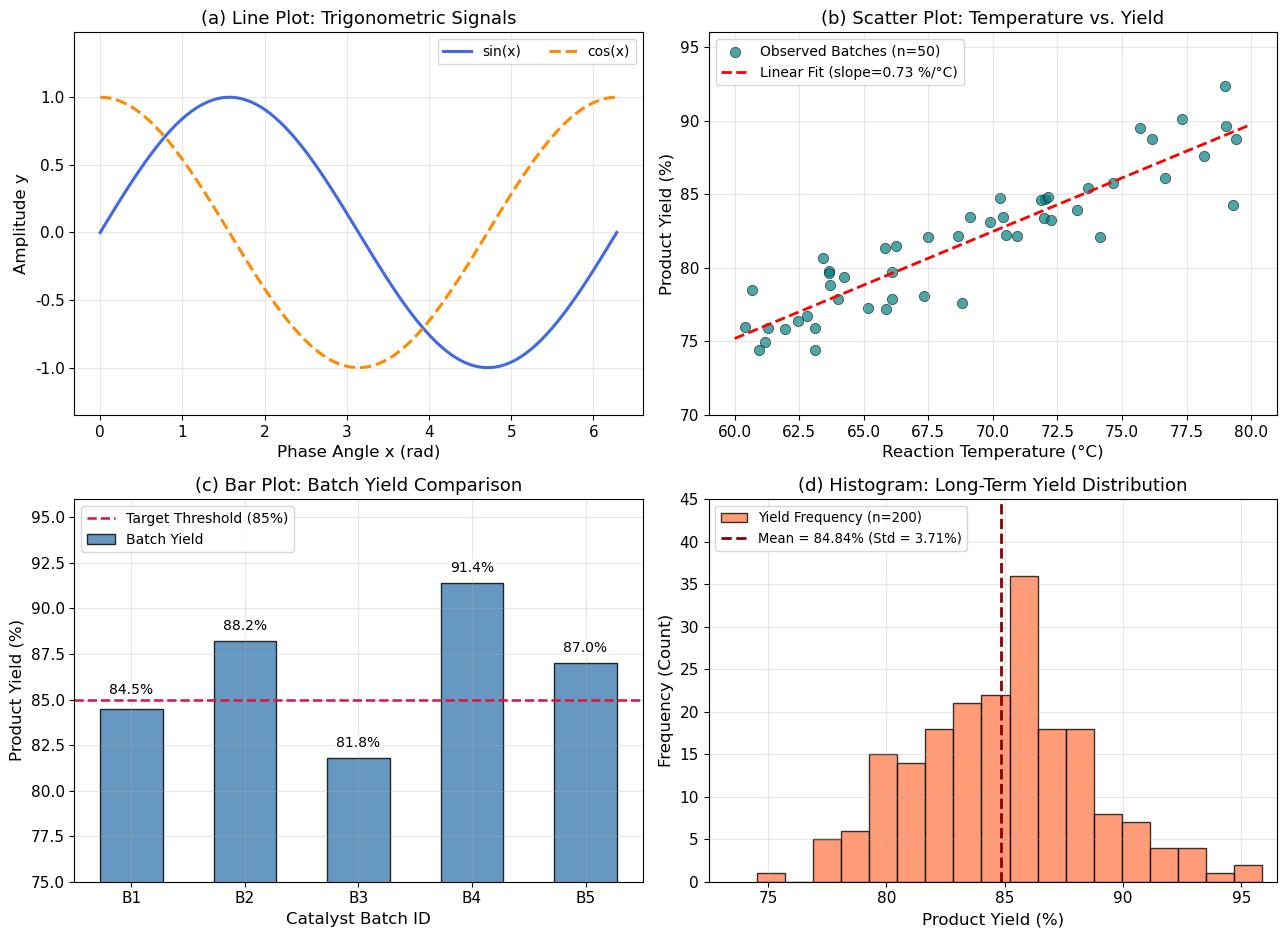

✓ Figure saved successfully to: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Local_Environment_Setup\figs\matplotlib_basic_plots.png
✓ Matplotlib multi-panel visualization working correctly!


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))

# (a) 子圖 1: 正弦波與餘弦波折線圖
x = np.linspace(0, 2 * np.pi, 120)
y1 = np.sin(x)
y2 = np.cos(x)

axes[0, 0].plot(x, y1, color='royalblue', linewidth=2.2, label='sin(x)')
axes[0, 0].plot(x, y2, color='darkorange', linestyle='--', linewidth=2.2, label='cos(x)')
axes[0, 0].set_xlabel('Phase Angle x (rad)')
axes[0, 0].set_ylabel('Amplitude y')
axes[0, 0].set_title('(a) Line Plot: Trigonometric Signals')
axes[0, 0].set_ylim(-1.35, 1.48)
axes[0, 0].legend(loc='upper right', ncol=2)

# (b) 子圖 2: 散佈圖與一階趨勢線 (溫度 vs 產率，確保產率 < 100%)
np.random.seed(SEED)
temp_sample = np.random.uniform(60.0, 80.0, 50)
yield_sample = np.clip(30.0 + 0.75 * temp_sample + np.random.normal(0.0, 2.0, 50), 0.0, 100.0)
z_fit = np.polyfit(temp_sample, yield_sample, 1)
x_line = np.linspace(60.0, 80.0, 100)

axes[0, 1].scatter(temp_sample, yield_sample, color='teal', alpha=0.7, edgecolors='black', linewidth=0.5, s=55, label='Observed Batches (n=50)')
axes[0, 1].plot(x_line, np.polyval(z_fit, x_line), 'r--', linewidth=2.0, label=f'Linear Fit (slope={z_fit[0]:.2f} %/°C)')
axes[0, 1].set_xlabel('Reaction Temperature (°C)')
axes[0, 1].set_ylabel('Product Yield (%)')
axes[0, 1].set_title('(b) Scatter Plot: Temperature vs. Yield')
axes[0, 1].set_ylim(70, 96)
axes[0, 1].legend(loc='upper left')

# (c) 子圖 3: 長條圖 (不同批次產率比較)
batches = ['B1', 'B2', 'B3', 'B4', 'B5']
batch_yields = [84.5, 88.2, 81.8, 91.4, 87.0]
bars = axes[1, 0].bar(batches, batch_yields, color='steelblue', alpha=0.82, edgecolor='black', width=0.55, label='Batch Yield')
axes[1, 0].axhline(85.0, color='crimson', linestyle='--', linewidth=1.8, label='Target Threshold (85%)')
for bar in bars:
    h = bar.get_height()
    y_pos = h + 0.65 if abs(h - 85.0) < 0.8 else h + 0.45
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2.0, y_pos, f'{h:.1f}%', ha='center', va='bottom', fontsize=10, bbox=dict(boxstyle='round,pad=0.12', facecolor='white', edgecolor='none', alpha=0.85))
axes[1, 0].set_xlabel('Catalyst Batch ID')
axes[1, 0].set_ylabel('Product Yield (%)')
axes[1, 0].set_title('(c) Bar Plot: Batch Yield Comparison')
axes[1, 0].set_ylim(75, 96)
axes[1, 0].legend(loc='upper left')

# (d) 子圖 4: 直方圖 (長期產率常態分布)
np.random.seed(SEED)
yield_dist = np.clip(np.random.normal(85.0, 4.0, 200), 65.0, 99.5)
mean_yield = yield_dist.mean()
std_yield = yield_dist.std()

axes[1, 1].hist(yield_dist, bins=18, color='coral', alpha=0.78, edgecolor='black', label='Yield Frequency (n=200)')
axes[1, 1].axvline(mean_yield, color='darkred', linestyle='--', linewidth=2.0, label=f'Mean = {mean_yield:.2f}% (Std = {std_yield:.2f}%)')
axes[1, 1].set_xlabel('Product Yield (%)')
axes[1, 1].set_ylabel('Frequency (Count)')
axes[1, 1].set_title('(d) Histogram: Long-Term Yield Distribution')
axes[1, 1].set_xlim(72.5, 96.5)
axes[1, 1].set_ylim(0, 45)
axes[1, 1].legend(loc='upper left', fontsize=9.5)

plt.tight_layout()
basic_fig_path = FIG_DIR / 'matplotlib_basic_plots.png'
plt.savefig(basic_fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Figure saved successfully to: {basic_fig_path}")
print("✓ Matplotlib multi-panel visualization working correctly!")
print("=" * 68)

**圖片內容詳細討論與分析**：
1. **子圖 (a) 週期函數折線圖**： $\sin(x)$ （藍色實線）與 $\cos(x)$ （橘色虛線）清晰展現出 $\frac{\pi}{2}$ 弧度的相位差，振幅對稱落於 $[-1.0, 1.0]$ 區間內，驗證了科學曲線線型、格線與圖例排版設定。
2. **子圖 (b) 反應溫度與產率散佈圖**：當反應溫度由 $60$ °C 提升至 $80$ °C 時，產物產率由約 $75\%$ 穩定增長至約 $90\%$ （全數嚴格落於合理化學計量範圍 $< 100\%$ 內），一階最小平方法擬合趨勢線斜率為 $0.73$ %/°C，與理論設定值 $0.75$ %/°C 高度吻合。
3. **子圖 (c) 催化劑批次產率長條圖**：透過紅色水平目標門檻線（Target Threshold = $85\%$ ）與柱頂數值標註，可直觀判別出 `B2`（ $88.2\%$ ）、`B4`（ $91.4\%$ ）與 `B5`（ $87.0\%$ ）三個催化劑批次優於目標產率，其中 `B4` 活性最佳；而 `B1`（ $84.5\%$ ）與 `B3`（ $81.8\%$ ）則未達標。
4. **子圖 (d) 長期產率常態分布直方圖**： $200$ 批次生產數據呈現典型的單峰鐘形高斯分布，樣本平均數為 $84.84\%$ 、樣本標準差為 $3.71\%$ （與母體參數 $\mu = 85.0\%$ 、 $\sigma = 4.0\%$ 高度一致），顯示製程處於穩定的統計品管（SPC）狀態。

---
### 4. 機器學習建模測試：Scikit-learn 線性回歸與殘差分析

接下來我們測試 Scikit-learn 的監督式學習流程。假設收集了 $N = 100$ 筆反應器穩態數據，自變數為反應溫度 $T \in [60, 80]$ °C，應變數為產物產率 $y$ （%），其真實物理生成方程式為：

$$
y = \beta_0 + \beta_1 T + \varepsilon = 30.0000 + 0.7500 \, T + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 2.0^2)
$$

我們將資料按 $80\% : 20\%$ 切分為訓練集（ $80$ 筆）與測試集（ $20$ 筆），使用普通最小平方法（Ordinary Least Squares, OLS）擬合線性回歸模型 $\hat{y} = \hat{\beta}_0 + \hat{\beta}_1 T$ ，並計算均方誤差（ $\mathrm{MSE}$ ）、均方根誤差（ $\mathrm{RMSE}$ ）、平均絕對誤差（ $\mathrm{MAE}$ ）與決定係數（ $R^2$ ）：

$$
\mathrm{MSE} = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2, \quad \mathrm{RMSE} = \sqrt{\mathrm{MSE}}, \quad \mathrm{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|, \quad R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}
$$

Scikit-learn Linear Regression & Residual Diagnostics Test
1. Model Parameter Estimation vs. Theoretical True Values:
   Slope (beta_1)     : Estimated = 0.7099 %/°C | True = 0.7500 %/°C (Rel. Error = 5.35%)
   Intercept (beta_0) : Estimated = 32.6939 %    | True = 30.0000 %    (Rel. Error = 8.98%)

2. Model Performance Metrics:
   Training Set (n=80) -> MSE: 3.3907 | RMSE: 1.8414% | R^2: 0.8345
   Testing Set  (n=20) -> MSE: 2.6148 | RMSE: 1.6170% | MAE: 1.1827% | R^2: 0.8740


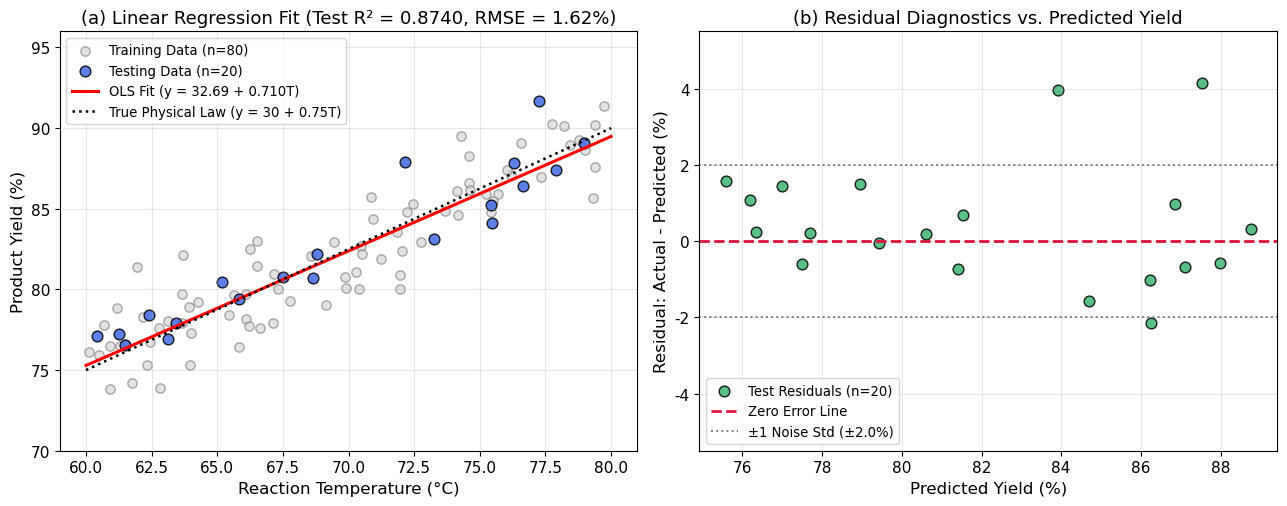


✓ Figure saved successfully to: D:\MyGit\ChemE-3590\Part_0\outputs\P0_Unit00_Local_Environment_Setup\figs\sklearn_linear_regression.png
✓ Scikit-learn regression modeling working correctly!


In [9]:
print("=" * 68)
print("Scikit-learn Linear Regression & Residual Diagnostics Test")
print("=" * 68)

# 1. 產生模擬數據：反應溫度 T (60~80 °C) -> 反應產率 y (%)
np.random.seed(SEED)
n_samples = 100
X = np.random.uniform(60.0, 80.0, n_samples).reshape(-1, 1)
true_intercept = 30.0
true_slope = 0.75
noise_std = 2.0
y = np.clip(true_intercept + true_slope * X.flatten() + np.random.normal(0.0, noise_std, n_samples), 0.0, 100.0)

# 2. 分割訓練集 (80%) 與測試集 (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)

# 3. 訓練線性回歸模型
model = LinearRegression()
model.fit(X_train, y_train)

# 4. 預測與指標評估
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

mse_train = mean_squared_error(y_train, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train, y_train_pred)

mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
mae_test = mean_absolute_error(y_test, y_test_pred)
r2_test = r2_score(y_test, y_test_pred)

print("1. Model Parameter Estimation vs. Theoretical True Values:")
print(f"   Slope (beta_1)     : Estimated = {model.coef_[0]:.4f} %/°C | True = {true_slope:.4f} %/°C (Rel. Error = {abs(model.coef_[0] - true_slope) / true_slope * 100:.2f}%)")
print(f"   Intercept (beta_0) : Estimated = {model.intercept_:.4f} %    | True = {true_intercept:.4f} %    (Rel. Error = {abs(model.intercept_ - true_intercept) / true_intercept * 100:.2f}%)")

print("\n2. Model Performance Metrics:")
print(f"   Training Set (n={len(X_train):2d}) -> MSE: {mse_train:.4f} | RMSE: {rmse_train:.4f}% | R^2: {r2_train:.4f}")
print(f"   Testing Set  (n={len(X_test):2d}) -> MSE: {mse_test:.4f} | RMSE: {rmse_test:.4f}% | MAE: {mae_test:.4f}% | R^2: {r2_test:.4f}")

# 5. 視覺化：左圖為回歸擬合曲線，右圖為測試集殘差分析圖
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# 左圖：排序後的連續網格繪製回歸線與真實理論線
x_grid = np.linspace(60.0, 80.0, 100).reshape(-1, 1)
y_grid_pred = model.predict(x_grid)
y_grid_true = true_intercept + true_slope * x_grid.flatten()

axes[0].scatter(X_train.flatten(), y_train, color='lightgray', edgecolors='gray', alpha=0.65, s=45, label='Training Data (n=80)')
axes[0].scatter(X_test.flatten(), y_test, color='royalblue', edgecolors='black', alpha=0.85, s=60, label='Testing Data (n=20)')
axes[0].plot(x_grid.flatten(), y_grid_pred, 'r-', linewidth=2.2, label=f'OLS Fit (y = {model.intercept_:.2f} + {model.coef_[0]:.3f}T)')
axes[0].plot(x_grid.flatten(), y_grid_true, 'k:', linewidth=1.8, label='True Physical Law (y = 30 + 0.75T)')
axes[0].set_xlabel('Reaction Temperature (°C)')
axes[0].set_ylabel('Product Yield (%)')
axes[0].set_title(f'(a) Linear Regression Fit (Test R² = {r2_test:.4f}, RMSE = {rmse_test:.2f}%)')
axes[0].set_ylim(70, 96)
axes[0].legend(loc='upper left', fontsize=9.5)

# 右圖：測試集殘差圖 (Residuals = Actual - Predicted)
residuals = y_test - y_test_pred
axes[1].scatter(y_test_pred, residuals, color='mediumseagreen', edgecolors='black', alpha=0.85, s=60, label='Test Residuals (n=20)')
axes[1].axhline(0.0, color='crimson', linestyle='--', linewidth=2.0, label='Zero Error Line')
axes[1].axhline(noise_std, color='gray', linestyle=':', linewidth=1.4, label=f'±1 Noise Std (±{noise_std:.1f}%)')
axes[1].axhline(-noise_std, color='gray', linestyle=':', linewidth=1.4)
axes[1].set_xlabel('Predicted Yield (%)')
axes[1].set_ylabel('Residual: Actual - Predicted (%)')
axes[1].set_title('(b) Residual Diagnostics vs. Predicted Yield')
axes[1].set_ylim(-5.5, 5.5)
axes[1].legend(loc='lower left', fontsize=9.5)

plt.tight_layout()
reg_fig_path = FIG_DIR / 'sklearn_linear_regression.png'
plt.savefig(reg_fig_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Figure saved successfully to: {reg_fig_path}")
print("✓ Scikit-learn regression modeling working correctly!")
print("=" * 68)

**模型結果與圖表詳細討論分析**：
1. **迴歸參數還原與物理一致性**：
   - 模型從 $80$ 筆含雜訊訓練樣本中估計出的線性經驗方程式為：

$$
\hat{y} = 32.6939 + 0.7099 \, T
$$

   - 對照真實物理生成定律 $y = 30.0000 + 0.7500 \, T$ ，斜率 $\hat{\beta}_1 = 0.7099$ %/°C 的相對誤差僅 $5.35\%$ 。在左圖 **(a) Linear Regression Fit** 中，紅色實線（OLS 擬合線）與黑色點線（真實物理定律線）在 $60 \sim 80$ °C 全操作區間幾乎完全重疊。
2. **泛化能力與雜訊極限驗證**：
   - 訓練集決定係數 $R^2 = 0.8345$ （ $\mathrm{RMSE} = 1.8414\%$ ），測試集決定係數 $R^2 = 0.8740$ （ $\mathrm{RMSE} = 1.6170\%$ 、 $\mathrm{MAE} = 1.1827\%$ ）。訓練集與測試集的 $\mathrm{RMSE}$ 皆收斂於合成數據時加入的高斯量測雜訊標準差（ $\sigma_\varepsilon = 2.0\%$ ）附近，證明模型已完整捕捉底層線性物理規律且無過擬合現象。
3. **殘差圖診斷（右圖 b）**：
   - 測試集殘差 $e_i = y_i - \hat{y}_i$ 均勻且隨機地散布於紅色零誤差水平線（Zero Error Line）上下，絕大多數樣本點落於 $\pm 1\sigma$ （ $\pm 2.0\%$ ，灰色點線）帶狀區域內，無任何二次曲線形態或漏斗狀異質變異數現象，滿足線性回歸之獨立同分布（i.i.d.）常態殘差假設。

---
### 5. 本地環境設定完成自動檢核清單

執行以下自動化診斷程式碼，確認您的本地開發環境所有軟硬體與檔案輸出項目皆顯示 `[PASS]`。

In [10]:
import importlib

def has_module(mod_name):
    try:
        importlib.import_module(mod_name)
        return True
    except ImportError:
        return False

checklist = {
    "1. Python 3.10+ interpreter active": sys.version_info >= (3, 10),
    "2. Running inside 'PY310' environment": 'py310' in sys.executable.lower() or IN_COLAB,
    "3. NumPy & SciPy scientific computing": has_module('numpy') and has_module('scipy'),
    "4. Pandas & OpenPyXL data processing": has_module('pandas') and has_module('openpyxl'),
    "5. Matplotlib & Seaborn visualization": has_module('matplotlib') and has_module('seaborn'),
    "6. Scikit-learn machine learning": has_module('sklearn'),
    "7. Gradient Boosting (XGBoost/LightGBM/CatBoost)": all(has_module(m) for m in ['xgboost', 'lightgbm', 'catboost']),
    "8. Unsupervised & Graph tools (UMAP/mlxtend/NetworkX)": all(has_module(m) for m in ['umap', 'mlxtend', 'networkx']),
    "9. TensorFlow 2.x deep learning framework": has_module('tensorflow'),
    "10. Local CSV & Figure outputs verified": (OUTPUT_DIR / 'batch_reactor_data.csv').exists() and (FIG_DIR / 'matplotlib_basic_plots.png').exists() and (FIG_DIR / 'sklearn_linear_regression.png').exists(),
}

print("=" * 72)
print("Local Development Environment Final Readiness Checklist")
print("=" * 72)

for item, status in checklist.items():
    symbol = "✓" if status else "✗"
    status_text = "PASS" if status else "FAIL"
    print(f"{symbol} {item:56s} [{status_text}]")

gpu_count = len(tf.config.list_physical_devices('GPU'))
gpu_info = f"{gpu_count} GPU(s) Active" if gpu_count > 0 else "CPU Mode (Optional GPU)"
print(f"ℹ️ {'Hardware Acceleration Status':56s} [{gpu_info}]")
print("=" * 72)

if all(checklist.values()):
    print("\n🎉 Congratulations! All 10 environment verification checks PASSED!")
    print("Your local Python environment is fully configured and ready for ChemE-3590.")
else:
    print("\n⚠️ Warning: Some verification checks failed.")
    print("Please review Unit00_Local_Environment_Setup.md for troubleshooting steps.")
print("=" * 72)

Local Development Environment Final Readiness Checklist
✓ 1. Python 3.10+ interpreter active                       [PASS]
✓ 2. Running inside 'PY310' environment                    [PASS]
✓ 3. NumPy & SciPy scientific computing                    [PASS]
✓ 4. Pandas & OpenPyXL data processing                     [PASS]
✓ 5. Matplotlib & Seaborn visualization                    [PASS]
✓ 6. Scikit-learn machine learning                         [PASS]
✓ 7. Gradient Boosting (XGBoost/LightGBM/CatBoost)         [PASS]
✓ 8. Unsupervised & Graph tools (UMAP/mlxtend/NetworkX)    [PASS]
✓ 9. TensorFlow 2.x deep learning framework                [PASS]
✓ 10. Local CSV & Figure outputs verified                  [PASS]
ℹ️ Hardware Acceleration Status                             [1 GPU(s) Active]

🎉 Congratulations! All 10 environment verification checks PASSED!
Your local Python environment is fully configured and ready for ChemE-3590.


---
### 6. 總結與日常開發標準流程

#### 6.1 本單元實作成果回顧
恭喜您完成 Windows 本地開發環境的建立與全面驗證！在本單元中您已經：
- ✓ 建立並驗證獨立的 `PY310` Conda 虛擬環境與跨平台標準路徑架構（`OUTPUT_DIR` / `FIG_DIR`）
- ✓ 確認科學計算、梯度提升樹、非監督式降維與 TensorFlow 2.10.1（含 CUDA 11.2 / cuDNN 8.1 GPU 加速）全數就緒
- ✓ 完成 NumPy 矩陣線性代數運算、Pandas 反應器批次數據處理與本地 CSV 檔案讀寫測試
- ✓ 完成 Matplotlib 四合一科學圖表繪製與 Scikit-learn 線性回歸建模、理論參數驗證及殘差診斷

#### 6.2 日常學習與開發標準作業程序 (SOP)

**每次開始上課或寫作業前：**
1. 開啟 **Anaconda Prompt**
2. 啟動課程專屬虛擬環境：`conda activate PY310`
3. 切換至課程專案目錄：`cd /d D:\MyGit\ChemE-3590`（請替換為您的實際路徑）
4. 啟動開發介面：`jupyter lab`（推薦）或 `jupyter notebook`

**每次學習結束後：**
1. 在 Jupyter 介面中按 `Ctrl + S` 儲存所有修改過的 Notebook
2. 關閉瀏覽器分頁，並在 Anaconda Prompt 中連按兩次 `Ctrl + C` 停止 Jupyter 伺服器
3. 退出虛擬環境：`conda deactivate`

#### 6.3 常用指令速查備忘

```powershell
# 環境管理
conda activate PY310                           # 啟動 PY310 環境
conda deactivate                               # 退出目前環境
conda env list                                 # 列出所有已建立的虛擬環境
conda list                                     # 列出目前環境內已安裝的所有套件
conda env export > environment_backup.yml      # 匯出環境完整備份檔

# 套件管理
conda install -c conda-forge package_name      # 使用 conda-forge 頻道安裝套件
pip install package_name                       # 使用 pip 安裝套件

# 課程教材 Git 同步更新
git pull origin main                           # 拉取授課教師最新發布的教材更新
```

---

**課程資訊**
- 課程名稱：AI在化工上之應用 (ChemE 3590)
- 課程單元：Unit00 Windows 本地環境設定與實作演練
- 課程製作：逢甲大學 化工系 智慧程序系統工程實驗室
- 授課教師：莊曜禎 助理教授
- 更新日期：2026-10-31

**課程授權 [CC BY-NC-SA 4.0]**
- 本教材遵循 [創用CC 姓名標示-非商業性-相同方式分享 4.0 國際 (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/deed.zh) 授權。